# Experiment 5: Reinforcement learning (tabular Q-learning)
5 x 7 grid world with walls, a goal (+10), a pit (-10) and a step cost (-0.1).
Q-learning for four exploration rates; the greedy policy is checked against value iteration.

In [1]:
import json, os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

os.makedirs('figs', exist_ok=True)
mpl.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'],
                     'font.size': 10, 'axes.grid': True, 'grid.color': '0.88', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.4,
                     'legend.frameon': False, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
R = {}

## 1. The environment (MDP)

In [2]:
H, W = 5, 7
WALLS = {(1, 2), (2, 2), (3, 2), (1, 4), (2, 4)}
GOAL, PIT, START = (0, W-1), (2, W-1), (H-1, 0)
A = [(-1, 0), (1, 0), (0, -1), (0, 1)]          # up, down, left, right
R_GOAL, R_PIT, R_STEP = 10.0, -10.0, -0.1

def step(s, a):
    r, c = s; dr, dc = A[a]; nr, nc = r + dr, c + dc
    if not (0 <= nr < H and 0 <= nc < W) or (nr, nc) in WALLS:
        nr, nc = r, c                           # bumping a wall wastes the step
    ns = (nr, nc)
    if ns == GOAL: return ns, R_GOAL, True
    if ns == PIT:  return ns, R_PIT, True
    return ns, R_STEP, False

## 2. Q-learning

In [3]:
ALPHA, GAMMA, EPISODES, CAP, SEED = 0.5, 0.95, 600, 120, 0

def train(eps, episodes=EPISODES, alpha=ALPHA, gamma=GAMMA, seed=SEED):
    rng = np.random.default_rng(seed)
    Q = np.zeros((H, W, 4))
    curve, first_goal = [], None
    for ep in range(episodes):
        s, total = START, 0.0
        for _ in range(CAP):                    # step cap per episode
            if rng.random() < eps:
                a = int(rng.integers(4))        # explore
            else:
                a = int(np.argmax(Q[s[0], s[1]]))   # exploit
            ns, r, done = step(s, a)
            total += r
            target = r + gamma*np.max(Q[ns[0], ns[1]])*(not done)   # no future after a terminal state
            Q[s[0], s[1], a] += alpha*(target - Q[s[0], s[1], a])   # TD update
            s = ns
            if done:
                break
        if first_goal is None and s == GOAL:
            first_goal = ep
        curve.append(total)
    return Q, np.array(curve), first_goal

def greedy_return(Q):
    """Return of one purely greedy episode (eps = 0) from START with the learned table."""
    s, total = START, 0.0
    for _ in range(CAP):
        s, r, done = step(s, int(np.argmax(Q[s[0], s[1]])))
        total += r
        if done: break
    return total

## 3. Optimal policy by value iteration (the known answer to check against)

In [4]:
V = np.zeros((H, W))
for _ in range(500):
    for r in range(H):
        for c in range(W):
            if (r, c) in WALLS or (r, c) in (GOAL, PIT): continue
            V[r, c] = max(rew + GAMMA*V[ns]*(not d) for ns, rew, d in (step((r, c), a) for a in range(4)))
def optimal_actions(s):
    q = [rew + GAMMA*V[ns]*(not d) for ns, rew, d in (step(s, a) for a in range(4))]
    return {a for a in range(4) if q[a] >= max(q) - 1e-9}
free = [(r, c) for r in range(H) for c in range(W) if (r, c) not in WALLS and (r, c) not in (GOAL, PIT)]
opt_return = greedy_return(np.stack([[[V[step((r, c), a)[0]]*(not step((r, c), a)[2]) + step((r, c), a)[1]
                                       for a in range(4)] for c in range(W)] for r in range(H)]))
print('optimal return from START:', round(opt_return, 2))
R['optimal_return'] = opt_return

optimal return from START: 9.1


## 4. Exploration rate

eps=0.01: last-100 mean 9.08 (10 seeds 9.07 ± 0.06), first goal ep 3, greedy return 9.10, optimal action in 26/28 cells


eps=0.10: last-100 mean 9.00 (10 seeds 8.83 ± 0.25), first goal ep 1, greedy return 9.10, optimal action in 26/28 cells


eps=0.20: last-100 mean 8.86 (10 seeds 8.81 ± 0.06), first goal ep 3, greedy return 9.10, optimal action in 28/28 cells


eps=0.50: last-100 mean 7.44 (10 seeds 7.54 ± 0.38), first goal ep 0, greedy return 9.10, optimal action in 28/28 cells


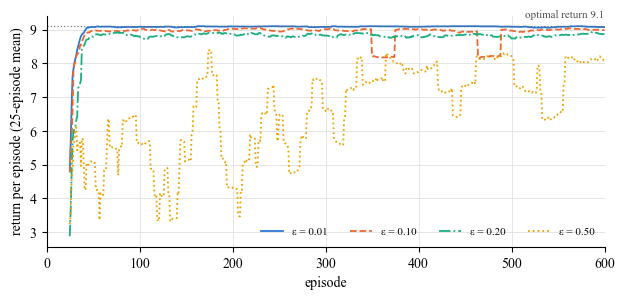

In [5]:
def smooth(v, k=25):
    return np.convolve(v, np.ones(k)/k, mode='valid')

EPS = (0.01, 0.10, 0.20, 0.50)
results, Qs = [], {}
for eps in EPS:
    Q, curve, fg = train(eps)
    Qs[eps] = Q
    pol_ok = sum(int(np.argmax(Q[s])) in optimal_actions(s) for s in free)
    multi = [train(eps, seed=sd)[1][-100:].mean() for sd in range(10)]    # 10 seeds for the spread
    results.append(dict(eps=eps, mean_last100=float(curve[-100:].mean()), first_goal_episode=fg,
                        greedy_return=greedy_return(Q), optimal_cells=pol_ok, free_cells=len(free),
                        seeds_mean=float(np.mean(multi)), seeds_sd=float(np.std(multi)), curve=curve.tolist()))
    print(f'eps={eps:.2f}: last-100 mean {curve[-100:].mean():.2f} (10 seeds {np.mean(multi):.2f} ± {np.std(multi):.2f}), '
          f'first goal ep {fg}, greedy return {greedy_return(Q):.2f}, optimal action in {pol_ok}/{len(free)} cells')
R['eps'] = [{k: v for k, v in r.items() if k != 'curve'} for r in results]
R['params'] = dict(H=H, W=W, walls=sorted(WALLS), goal=GOAL, pit=PIT, start=START, alpha=ALPHA, gamma=GAMMA,
                   episodes=EPISODES, cap=CAP, seed=SEED)

fig, ax = plt.subplots(figsize=(7.2, 3.0))
for r, c, ls in zip(results, C, ['-', '--', '-.', ':']):
    sm = smooth(np.array(r['curve']))
    ax.plot(np.arange(len(sm)) + 25, sm, color=c, ls=ls, lw=1.3, label=f"ε = {r['eps']:.2f}")
ax.axhline(opt_return, color='0.4', lw=0.8, ls=(0, (1, 2)))
ax.text(600, opt_return + 0.25, f'optimal return {opt_return:.1f}', ha='right', fontsize=8, color='0.3')
ax.set_xlabel('episode'); ax.set_ylabel('return per episode (25-episode mean)')
ax.set_xlim(0, 600); ax.legend(loc='lower right', fontsize=8, ncol=4)
fig.savefig('figs/fig5_1_learning_curves.png'); plt.show()

## 5. The greedy policy at eps = 0.20, drawn as arrows

→ → → → → → G
→ ↑ # ↑ # ↑ ↑
↑ ↑ # ↑ # ↑ P
↑ ↑ # ↑ → ↑ ←
↑ → → ↑ → ↑ ←
eps=0.20 and eps=0.50 greedy policies agree in 21/28 cells


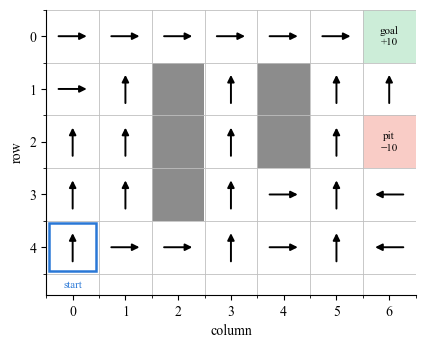

In [6]:
Q = Qs[0.20]
policy = np.argmax(Q, axis=2)
arrows = '↑↓←→'
grid_txt = []
for r in range(H):
    row = []
    for c in range(W):
        s = (r, c)
        row.append('#' if s in WALLS else 'G' if s == GOAL else 'P' if s == PIT else arrows[policy[r, c]])
    grid_txt.append(' '.join(row)); print(' '.join(row))
R['policy_grid_eps020'] = grid_txt
same_as_05 = sum(int(np.argmax(Qs[0.20][s])) == int(np.argmax(Qs[0.50][s])) for s in free)
R['policy_agreement_020_050'] = same_as_05
print(f'eps=0.20 and eps=0.50 greedy policies agree in {same_as_05}/{len(free)} cells')

fig, ax = plt.subplots(figsize=(5.0, 3.7))
img = np.ones((H, W, 3))
for (r, c) in WALLS: img[r, c] = (0.55, 0.55, 0.55)
img[GOAL] = (0.80, 0.93, 0.85); img[PIT] = (0.98, 0.80, 0.78)
ax.imshow(img, extent=(-0.5, W-0.5, H-0.5, -0.5))
d = {0: (0, -0.32), 1: (0, 0.32), 2: (-0.32, 0), 3: (0.32, 0)}
for (r, c) in free:
    dx, dy = d[int(policy[r, c])]
    good = int(policy[r, c]) in optimal_actions((r, c))
    ax.annotate('', xy=(c + dx, r + dy), xytext=(c - dx, r - dy),
                arrowprops=dict(arrowstyle='-|>', color='k' if good else C[1], lw=1.4))
ax.text(*GOAL[::-1], 'goal\n+10', ha='center', va='center', fontsize=8)
ax.text(*PIT[::-1], 'pit\n−10', ha='center', va='center', fontsize=8)
ax.add_patch(plt.Rectangle((START[1]-0.45, START[0]-0.45), 0.9, 0.9, fill=False, ec=C[0], lw=1.8))
ax.text(START[1], START[0] + 0.62, 'start', ha='center', va='top', fontsize=8, color=C[0])
ax.set_xticks(range(W)); ax.set_yticks(range(H)); ax.grid(False)
ax.set_xticks(np.arange(-0.5, W), minor=True); ax.set_yticks(np.arange(-0.5, H), minor=True)
ax.grid(which='minor', color='0.75', lw=0.6)
ax.set_xlabel('column'); ax.set_ylabel('row')
ax.set_ylim(H - 0.5 + 0.4, -0.5)
fig.savefig('figs/fig5_2_policy.png'); plt.show()

In [7]:
with open('results.json', 'w') as fh:
    json.dump(R, fh, indent=1)
print('saved results.json')

saved results.json
